In [1]:
#hide
! [ -e /content ] && pip install -Uqq fastbook
import fastbook
fastbook.setup_book()

In [2]:
#hide
from fastai.vision.all import *
from fastbook import *

matplotlib.rc('image', cmap='Greys')

# Stochastic Gradient Descent (SGD)

Alternative method to predict the handwritten numbers.

Instead of trying to find the similarity between an image and an "ideal image," we could instead look at each individual pixel and come up with a set of weights for each one, such that the highest weights are associated with those pixels most likely to be black for a particular category. For instance, pixels toward the bottom right are not very likely to be activated for a 7, so they should have a low weight for a 7, but they are likely to be activated for an 8, so they should have a high weight for an 8. This can be represented as a function and set of weight values for each possible category—for instance the probability of being the number 8:

```def pr_eight(x,w): return (x*w).sum()```

Here we are assuming that ```x``` is the image, represented as a vector—in other words, with all of the rows stacked up end to end into a single long line. And we are assuming that the weights are a vector ```w```.

Searching for the best vector w is a way to search for the best function for recognising 8s. (Because we are not yet using a deep neural network, we are limited by what our function can actually do). 

To be more specific, here are the steps that we are going to require, to turn this function into a machine learning classifier:

1. *Initialize* the weights.
2. For each image, use these weights to *predict* whether it appears to be a 3 or a 7.
3. Based on these predictions, calculate how good the model is (its *loss*).
4. Calculate the *gradient*, which measures for each weight, how changing that weight would change the loss
5. *Step* (that is, change) all the weights based on that calculation.
6. Go back to the step 2, and *repeat* the process.
7. Iterate until you decide to *stop* the training process (for instance, because the model is good enough or you don't want to wait any longer).

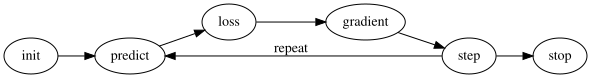

In [3]:
#id gradient_descent
#caption The gradient descent process
#alt Graph showing the steps for Gradient Descent
gv('''
init->predict->loss->gradient->step->stop
step->predict[label=repeat]
''')

Initialize:: We initialize the parameters to random values. 

Loss:: This is what Samuel referred to when he spoke of *testing the effectiveness of any current weight assignment in terms of actual performance*. We need some function that will return a number that is small if the performance of the model is good (the standard approach is to treat a small loss as good, and a large loss as bad, although this is just a convention).

Step:: A simple way to figure out whether a weight should be increased a bit, or decreased a bit, would be just to try it: increase the weight by a small amount, and see if the loss goes up or down. Once you find the correct direction, you could then change that amount by a bit more, and a bit less, until you find an amount that works well. However, this is slow! As we will see, the magic of calculus allows us to directly figure out in which direction, and by roughly how much, to change each weight, without having to try all these small changes. The way to do this is by calculating *gradients* (using differentiation). This is just a performance optimization, we would get exactly the same results by using the slower manual process as well.

Stop:: Once we've decided how many epochs to train the model for (a few suggestions for this were given in the earlier list), we apply that decision. This is where that decision is applied. For our digit classifier, we would keep training until the accuracy of the model started getting worse, or we ran out of time.


Here is how to get gradients using PyTorch.

First, pick a tensor value which we want gradients at:

In [4]:
xt = tensor(3.).requires_grad_()

```requires_grad_``` is the magical incantation we use to tell PyTorch that we want to calculate gradients with respect to that variable at that value. It is essentially tagging the variable, so PyTorch will remember to keep track of how to compute gradients of the other, direct calculations on it that you will ask for.

Now we calculate our function with that value.

In [5]:
def f(x): 
    return x**2
yt = f(xt)
yt

tensor(9., grad_fn=<PowBackward0>)

Finally, we tell PyTorch to calculate the gradients for us:

In [6]:
yt.backward()

The "backward" here refers to *backpropagation*, which is the name given to the process of calculating the derivative of each layer.
We can now view the gradients by checking the ```grad``` attribute of our tensor:

In [7]:
xt.grad

tensor(6.)

Which makes sense as, the gradient of ```x**2``` is ```6``` when ```x = 3```

Now we'll repeat the preceding steps, but with a vector argument for our function:

In [8]:
xt = tensor([3.,4.,10.]).requires_grad_()
xt

tensor([ 3.,  4., 10.], requires_grad=True)

And we'll add sum to our function so it can take a vector (i.e., a rank-1 tensor), and return a scalar (i.e., a rank-0 tensor):

In [9]:
def f(x): 
    return (x**2).sum()

yt = f(xt)
yt

tensor(125., grad_fn=<SumBackward0>)

Again, we tell PyTorch to calculate the gradient

In [10]:
yt.backward()
xt.grad

tensor([ 6.,  8., 20.])

Our gradients are 2*xt, as we'd expect

**Insight:** The gradients only tell us the slope of our function, they don't actually tell us exactly how far to adjust the parameters. But it gives us some idea of how far; if the slope is very large, then that may suggest that we have more adjustments to do, whereas if the slope is very small, that may suggest that we are close to the optimal value.

# Stepping With a Learning Rate

Deciding how to change our parameters based on the values of the gradients is an important part of the deep learning process. Nearly all approaches start with the basic idea of multiplying the gradient by some small number, called the learning rate (LR). The learning rate is often a number between 0.001 and 0.1, although it could be anything. Often, people select a learning rate just by trying a few, and finding which results in the best model after training. Once you've picked a learning rate, you can adjust your parameters using this simple function:

```w -= gradient(w) * lr```

This is known as *stepping* your parameters, using an *optimizer step*. Notice how we *subtract* the ```gradient * lr``` from the parameter to update it. This allows us to adjust the parameter in the direction of the slope by increasing the parameter when the slope is negative and decreasing the parameter when the slope is positive. We want to adjust our parameters in the direction of the slope because our goal in deep learning is to *minimize* the loss.

# An End-to-End SGD Example

Imagine you were measuring the speed of a roller coaster as it went over the top of a hump. It would start fast, and then get slower as it went up the hill; it would be slowest at the top, and it would then speed up again as it went downhill. You want to build a model of how the speed changes over time. If you were measuring the speed manually every second for 20 seconds, it might look something like this:

In [12]:
time = torch.arange(0,20).float(); time

tensor([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13., 14., 15., 16., 17., 18., 19.])

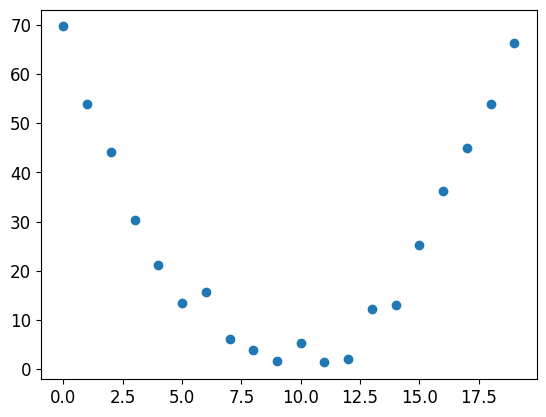

In [13]:
speed = torch.randn(20)*3 + 0.75*(time-9.5)**2 + 1
plt.scatter(time,speed);

We can't consider every possible function, so let's use a guess that it will be quadratic; i.e., a function of the form ```a*(time**2)+(b*time)+c```

We want to distinguish clearly between the function's input (the time when we are measuring the coaster's speed) and its parameters (the values that define *which* quadratic we're trying). So, let's collect the parameters in one argument and thus separate the input, ```t```, and the parameters, ```params```, in the function's signature:

In [29]:
def f(t, params):
    a,b,c = params
    return a*(t**2) + (b*t) + c

In other words, we've restricted the problem of finding the best imaginable function that fits the data, to finding the best quadratic function. This greatly simplifies the problem, since every quadratic function is fully defined by the three parameters ```a```, ```b```, and ```c```. Thus, to find the best quadratic function, we only need to find the best values for ```a```, ```b```, and ```c```.

We need to define first what we mean by "best." We define this precisely by choosing a *loss function*, which will return a value based on a prediction and a target, where lower values of the function correspond to "better" predictions. It is important for loss functions to return *lower* values when predictions are more accurate, as the SGD procedure we defined earlier will try to *minimize* this loss. For continuous data, it's common to use *mean squared error*:

In [30]:
def mse(preds, targets): 
    return ((preds-targets)**2).mean()

Now, let's work through our 7 step process.

#### Step 1: Initialize the parameters

First, we initialize the parameters to random values, and tell PyTorch that we want to track their gradients, using ```requires_grad_```:

In [41]:
params = torch.randn(3).requires_grad_()

# 3 - this argument is suggesting to create 3 random number

In [32]:
#hide
orig_params = params.clone()

#### Step 2: Calculate the predictions
Next, we calculate the predictions:

In [33]:
preds = f(time, params)

Let's create a little function to see how close our predictions are to our targets, and take a look:

In [20]:
def show_preds(preds, ax=None):
    if ax is None: ax=plt.subplots()[1]
    ax.scatter(time, speed)
    ax.scatter(time, to_np(preds), color='red')
    ax.set_ylim(-300,100)

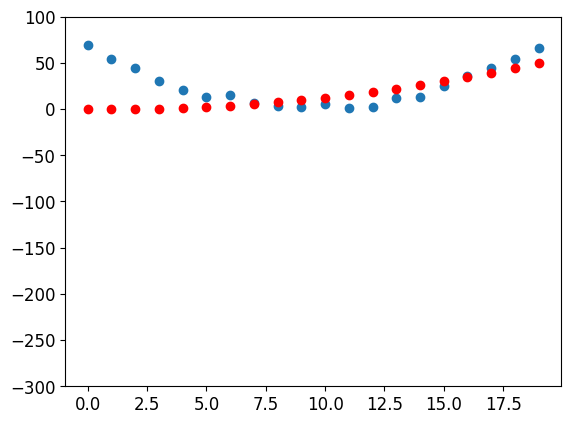

In [21]:
show_preds(preds)

#### Step 3: Calculate the loss
We calculate the loss as follows:

In [34]:
loss = mse(preds, speed)
loss

tensor(22559.9629, grad_fn=<MeanBackward0>)

Our goal is now to improve this. To do that, we'll need to know the gradients.

#### Step 4: Calculate the gradients
The next step is to calculate the gradients. In other words, calculate an approximation of how the parameters need to change:

In [35]:
loss.backward()
params.grad

tensor([49674.8438,  3194.6436,   201.2619])

We can use these gradients to improve our parameters. We'll need to pick a learning rate (we'll discuss how to do that in practice in the next chapter; for now we'll just use 1e-5, or 0.00001):

In [36]:
params.grad * 1e-5

tensor([0.4967, 0.0319, 0.0020])

In [37]:
params

tensor([ 0.9912,  0.4679, -0.2049], requires_grad=True)

#### Step 5: Step the weights.
Now we need to update the parameters based on the gradients we just calculated:

In [42]:
lr = 1e-5
params.data -= lr * params.grad.data
params.grad = None

AttributeError: 'NoneType' object has no attribute 'data'

> To calculate the gradients we call backward on the loss. But this loss was itself calculated by mse, which in turn took preds as an input, which was calculated using f taking as an input params, which was the object on which we originally called requires_grad_—which is the original call that now allows us to call backward on loss. This chain of function calls represents the mathematical composition of functions, which enables PyTorch to use calculus's chain rule under the hood to calculate these gradients.

Let's see if the loss has improved:

In [43]:
preds = f(time,params)
mse(preds, speed)

tensor(4758.8179, grad_fn=<MeanBackward0>)

And take a look at the plot:

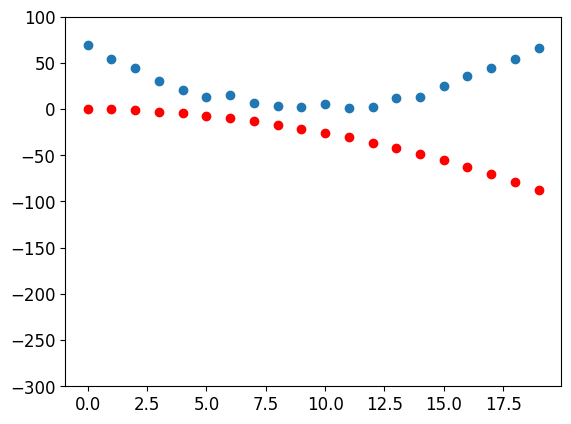

In [44]:
show_preds(preds)

We need to repeat this a few times, so we'll create a function to apply one step:

In [45]:
def apply_step(params, prn=True):
    preds = f(time, params)
    loss = mse(preds, speed)
    loss.backward()
    params.data -= lr * params.grad.data
    params.grad = None
    if prn: print(loss.item())
    return preds

#### Step 6: Repeat the process
Now we iterate. By looping and performing many improvements, we hope to reach a good result:

In [46]:
for i in range(10): 
    apply_step(params)

4758.81787109375
1404.3031005859375
769.5233154296875
649.400634765625
626.6668090820312
622.3619384765625
621.5443725585938
621.3868408203125
621.3539428710938
621.3448486328125


In [48]:
#hide
params = orig_params.detach().requires_grad_()

The loss is going down, just as we hoped! But looking only at these loss numbers disguises the fact that each iteration represents an entirely different quadratic function being tried, on the way to finding the best possible quadratic function. We can see this process visually if, instead of printing out the loss function, we plot the function at every step. Then we can see how the shape is approaching the best possible quadratic function for our data:

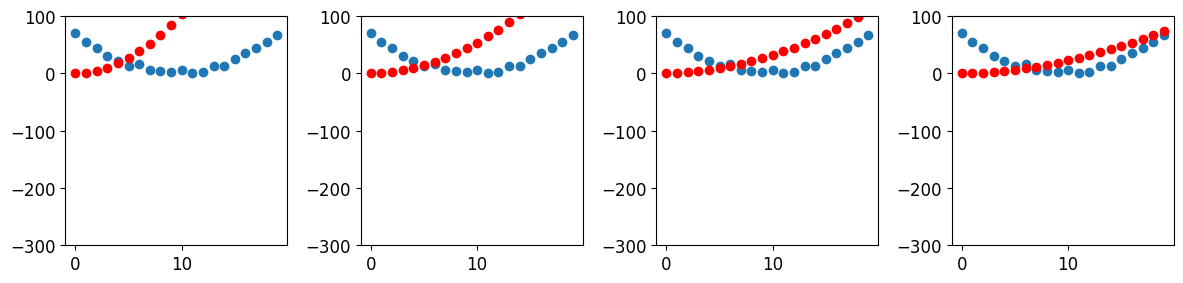

In [49]:
_,axs = plt.subplots(1,4,figsize=(12,3))
for ax in axs: show_preds(apply_step(params, False), ax)
plt.tight_layout()

#### Step 7: stop
We just decided to stop after 10 epochs arbitrarily. In practice, we would watch the training and validation losses and our metrics to decide when to stop, as we've discussed.

###Summarizing Gradient Descent

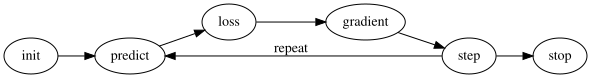

In [50]:
#hide_input
#id gradient_descent
#caption The gradient descent process
#alt Graph showing the steps for Gradient Descent
gv('''
init->predict->loss->gradient->step->stop
step->predict[label=repeat]
''')

To prevent errors, I need to run set of codes that was noted in Lesson04_1

In [51]:
# Download the dataset
path = untar_data(URLs.MNIST_SAMPLE)
Path.BASE_PATH = path

# Training images → stacked float tensors (needed for train_x)
threes = (path/'train'/'3').ls().sorted()
sevens = (path/'train'/'7').ls().sorted()
three_tensors = [tensor(Image.open(o)) for o in threes]
seven_tensors = [tensor(Image.open(o)) for o in sevens]
stacked_threes = torch.stack(three_tensors).float()/255
stacked_sevens = torch.stack(seven_tensors).float()/255

# Validation images (needed for valid_x)
valid_3_tens = torch.stack([tensor(Image.open(o)) for o in (path/'valid'/'3').ls()]).float()/255
valid_7_tens = torch.stack([tensor(Image.open(o)) for o in (path/'valid'/'7').ls()]).float()/255

<div><progress max="3214948" value="3219456"></progress> 100.14% [3219456/3214948 00:00&lt;00:00]</div>

# The MNIST Loss Function

We already have our independent variables ```x```—these are the images themselves. We'll concatenate them all into a single tensor, and also change them from a list of matrices (a rank-3 tensor) to a list of vectors (a rank-2 tensor). We can do this using ```view```, which is a PyTorch method that changes the shape of a tensor without changing its contents. ```-1``` is a special parameter to ```view``` that means "make this axis as big as necessary to fit all the data":

In [52]:
train_x = torch.cat([stacked_threes, stacked_sevens]).view(-1, 28*28)


We need a label for each image. We'll use ```1``` for 3s and ```0``` for 7s:

In [53]:
train_y = tensor([1]*len(threes) + [0]*len(sevens)).unsqueeze(1)
(train_x.shape,train_y.shape)

(torch.Size([12396, 784]), torch.Size([12396, 1]))

A ```Dataset``` in PyTorch is required to return a tuple of ```(x,y)``` when indexed. Python provides a ```zip``` function which, when combined with ```list```, provides a simple way to get this functionality:

In [57]:
valid_x = torch.cat([valid_3_tens, valid_7_tens]).view(-1, 28*28)
valid_y = tensor([1]*len(valid_3_tens) + [0]*len(valid_7_tens)).unsqueeze(1)
valid_dset = list(zip(valid_x,valid_y))

In [55]:
dset = list(zip(train_x,train_y))
(x,y) = dset[0]
(x.shape,y)

(torch.Size([784]), tensor([1]))

Now we need an (initially random) weight for every pixel (this is the *initialize* step in our seven-step process):

In [59]:
def init_params(size, std=1.0): 
    return (torch.randn(size)*std).requires_grad_()

In [62]:
weights = init_params((28*28,1))

The function ```weights*pixels``` won't be flexible enough—it is always equal to 0 when the pixels are equal to 0 (i.e., its *intercept* is 0). You might remember from high school math that the formula for a line is ```y=w*x+b```; we still need the ```b```. We'll initialize it to a random number too:

In [60]:
bias = init_params(1)

In neural networks, the ```w``` in the equation ```y=w*x+b``` is called the *weights*, and the b is called the *bias*. Together, the weights and bias make up the *parameters*.


We can now calculate a prediction for one image:

In [63]:
(train_x[0]*weights.T).sum() + bias

tensor([7.2203], grad_fn=<AddBackward0>)

To calculate the prediction for all of the images we use *matrix multiplication* (represented with a ```@``` operator):

In [64]:
def linear1(xb): 
    return xb@weights + bias
preds = linear1(train_x)
preds

tensor([[ 7.2203],
        [12.3349],
        [ 8.4846],
        ...,
        [-9.3458],
        [ 0.7169],
        [-5.8082]], grad_fn=<AddBackward0>)

This equation, ```batch@weights + bias```, is one of the two fundamental equations of any neural network (the other one is the activation function)

Let's check our accuracy. To decide if an output represents a 3 or a 7, we can just check whether it's greater than 0.0, so our accuracy for each item can be calculated

In [65]:
corrects = (preds>0.0).float() == train_y
corrects

tensor([[ True],
        [ True],
        [ True],
        ...,
        [ True],
        [False],
        [ True]])

In [66]:
corrects.float().mean().item()

0.7621006965637207

Now let's see what the change in accuracy is for a small change in one of the weights (note that we have to ask PyTorch not to calculate gradients as we do this, which is what with ```torch.no_grad()``` is doing here):

In [68]:
with torch.no_grad(): weights[0] *= 1.0001

In [69]:
preds = linear1(train_x)
((preds>0.0).float() == train_y).float().mean().item()

0.7621006965637207

What we did: we changed the weights slightly (1.0001) but the accuracy did not change. The gradient is dy/dx, and dy is the change in accuracy (which is 0) and dx is the change in weights (*= 1.001) So if we use the accuracy as the loss function, the output would be 0. 

So, let's try to use a loss function that can actually output something valuable, and not 0.

In [71]:
trgts  = tensor([1,0,1])
prds   = tensor([0.9, 0.4, 0.2])

Here's a first try at a loss function that measures the distance between ```predictions``` and ```targets```:

In [72]:
def mnist_loss(predictions, targets):
    return torch.where(targets==1, 1-predictions, predictions).mean()

```torch.where(a,b,c)``` is the short form for: for each position, if a is True take b, otherwise take c:
```
result = []
for i in range(len(a)):
    if a[i]:
        result.append(b[i])
    else:
        result.append(c[i])
```
it is also the same as list comprehension

In [73]:
torch.where(trgts==1, 1-prds, prds)

tensor([0.1000, 0.4000, 0.8000])

This function returns a lower number when predictions are more accurate, meaning when accurate predictions are more confident (higher absolute values), and when inaccurate predictions are less confident. In PyTorch, we always assume that a lower value of a loss function is better. Since we need a scalar for the final loss, ```mnist_loss``` takes the mean of the previous tensor:

In [74]:
mnist_loss(prds,trgts)

tensor(0.4333)

For instance, if we change our prediction for the one "false" target from ```0.2``` to ```0.8``` the loss will go down, indicating that this is a better prediction:

In [75]:
mnist_loss(tensor([0.9, 0.4, 0.8]),trgts)

tensor(0.2333)

One problem with mnist_loss as currently defined is that it assumes that predictions are always between 0 and 1. We need to ensure, then, that this is actually the case! As it happens, there is a function that does exactly that—let's take a look.

### Sigmoid

The ```sigmoid``` function always outputs a number between 0 and 1. It's defined as follows:

In [ ]:
def sigmoid(x): 
    return 1/(1+torch.exp(-x))

Pytorch defines an accelerated version for us, so we don’t really need our own. This is an important function in deep learning, since we often want to ensure values are between 0 and 1. This is what it looks like:

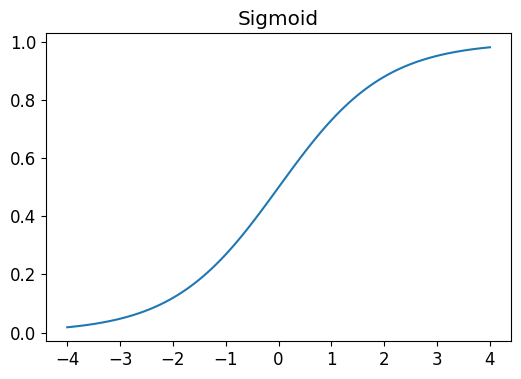

In [76]:
plot_function(torch.sigmoid, title='Sigmoid', min=-4, max=4)

As you can see, it takes any input value, positive or negative, and smooshes it onto an output value between 0 and 1. It's also a smooth curve that only goes up, which makes it easier for SGD to find meaningful gradients.

Let's update ```mnist_loss``` to first apply ```sigmoid``` to the inputs:

In [77]:
def mnist_loss(predictions, targets):
    predictions = predictions.sigmoid()
    return torch.where(targets==1, 1-predictions, predictions).mean()

We have now solved the problem that the predictions were not in between 0 and 1.

### SGD and Mini-Batches

Now that we have a loss function that is suitable for driving SGD, we can consider some of the details involved in the next phase of the learning process, which is to change or update the weights based on the gradients. This is called an *optimization step*.

> *mini-batch*: few data items selected to calculate the average loss one at a time
> *batch size*: The number of data items in the mini-batch

We train on *mini-batches* one at a time. Additionally, its good to shuffle the data so there is more variations.

A ```DataLoader``` can take any Python collection and turn it into an iterator over mini-batches, like so:

In [78]:
coll = range(15)
dl = DataLoader(coll, batch_size=5, shuffle=True)
list(dl)

[tensor([ 3, 12,  8, 10,  2]),
 tensor([ 9,  4,  7, 14,  5]),
 tensor([ 1, 13,  0,  6, 11])]

For training a model, we don't just want any Python collection, but a collection containing independent and dependent variables (that is, the inputs and targets of the model). A collection that contains tuples of independent and dependent variables is known in PyTorch as a ```Dataset```. Here's an example of an extremely simple ```Dataset```

In [79]:
ds = L(enumerate(string.ascii_lowercase))
ds

[(0, 'a'), (1, 'b'), (2, 'c'), (3, 'd'), (4, 'e'), (5, 'f'), (6, 'g'), (7, 'h'), (8, 'i'), (9, 'j'), (10, 'k'), (11, 'l'), (12, 'm'), (13, 'n'), (14, 'o'), (15, 'p'), (16, 'q'), (17, 'r'), (18, 's'), (19, 't'), (20, 'u'), (21, 'v'), (22, 'w'), (23, 'x'), (24, 'y'), (25, 'z')]

When we pass a Dataset to a DataLoader we will get back mini-batches which are themselves tuples of tensors representing batches of independent and dependent variables

In [80]:
dl = DataLoader(ds, batch_size=6, shuffle=True)
list(dl)

[(tensor([17, 18, 10, 22,  8, 14]), ('r', 's', 'k', 'w', 'i', 'o')),
 (tensor([20, 15,  9, 13, 21, 12]), ('u', 'p', 'j', 'n', 'v', 'm')),
 (tensor([ 7, 25,  6,  5, 11, 23]), ('h', 'z', 'g', 'f', 'l', 'x')),
 (tensor([ 1,  3,  0, 24, 19, 16]), ('b', 'd', 'a', 'y', 't', 'q')),
 (tensor([2, 4]), ('c', 'e'))]

We are now ready to write our first training loop for a model using SGD!

## Putting it All Together


It's time to implement the process we saw in gradient_descent. In code, our process will be implemented something like this for each epoch:
```
for x,y in dl:
    pred = model(x)
    loss = loss_func(pred, y)
    loss.backward()
    parameters -= parameters.grad * lr
```
First, let's re-initialize our parameters:

In [83]:
weights = init_params((28*28,1))
bias = init_params(1)

A ```DataLoader``` can be created from a ```Dataset```:

In [86]:
dl = DataLoader(dset, batch_size=256)
(xb,yb) = first(dl)
xb.shape,yb.shape

(torch.Size([256, 784]), torch.Size([256, 1]))

We'll do the same for the validation set:

In [87]:
valid_dl = DataLoader(valid_dset, batch_size=256)

Let's create a mini-batch of size 4 for testing:

In [88]:
batch = train_x[:4]
batch.shape

torch.Size([4, 784])

In [89]:
preds = linear1(batch)
preds

tensor([[-0.1258],
        [-5.5492],
        [-5.6918],
        [-5.5553]], grad_fn=<AddBackward0>)

In [90]:
loss = mnist_loss(preds, train_y[:4])
loss

tensor(0.8801, grad_fn=<MeanBackward0>)

Now we can calculate the gradients:

In [91]:
loss.backward()
weights.grad.shape,weights.grad.mean(),bias.grad

(torch.Size([784, 1]), tensor(-0.0093), tensor([-0.0650]))

Let's put that all in a function:

In [92]:
def calc_grad(xb, yb, model):
    preds = model(xb)
    loss = mnist_loss(preds, yb)
    loss.backward()

and test it:

In [93]:
calc_grad(batch, train_y[:4], linear1)
weights.grad.mean(),bias.grad

(tensor(-0.0186), tensor([-0.1300]))

But look what happens if we call it twice:

In [94]:
calc_grad(batch, train_y[:4], linear1)
weights.grad.mean(),bias.grad

(tensor(-0.0279), tensor([-0.1950]))

The gradients have changed! The reason for this is that ```loss.backward``` actually *adds* the gradients of ```loss``` to any gradients that are currently stored. So, we have to set the current gradients to 0 first:

In [95]:
weights.grad.zero_()
bias.grad.zero_();

>Inplace Operations: Methods in PyTorch whose names end in an underscore modify their objects *in place*. For instance, ```bias.zero_()``` sets all elements of the tensor ```bias``` to 0.

Now, we update the weights and biases based on the gradient and learning rate.

In [97]:
def train_epoch(model, lr, params):
    for xb,yb in dl:
        calc_grad(xb, yb, model)
        for p in params:
            p.data -= p.grad*lr
            p.grad.zero_()

We also want to check how we're doing, by looking at the accuracy of the validation set. To decide if an output represents a 3 or a 7, we can just check whether it's greater than 0. So our accuracy for each item can be calculated (using broadcasting, so no loops!) with:

In [104]:
(preds>0.0).float() == train_y[:4]

tensor([[False],
        [False],
        [False],
        [False]])

That gives us this function to calculate our validation accuracy:

In [102]:
def batch_accuracy(xb, yb):
    preds = xb.sigmoid()
    correct = (preds>0.5) == yb
    return correct.float().mean()

We can check it works:

In [103]:
batch_accuracy(linear1(batch), train_y[:4])

tensor(0.)

and then put the batches together:

In [105]:
def validate_epoch(model):
    accs = [batch_accuracy(model(xb), yb) for xb,yb in valid_dl]
    return round(torch.stack(accs).mean().item(), 4)

In [106]:
validate_epoch(linear1)

0.5707

That's our starting point. Let's train for one epoch, and see if the accuracy improves:

In [107]:
lr = 1.
params = weights,bias
train_epoch(linear1, lr, params)
validate_epoch(linear1)

0.7074

Then do a few more:

In [108]:
for i in range(20):
    train_epoch(linear1, lr, params)
    print(validate_epoch(linear1), end=' ')

0.8792 0.9252 0.9501 0.9608 0.9623 0.9671 0.9696 0.9715 0.972 0.973 0.9725 0.9725 0.9735 0.974 0.9745 0.975 0.975 0.9754 0.9754 0.9754 

Looking good! We're already about at the same accuracy as our "pixel similarity" approach, and we've created a general-purpose foundation we can build on. Our next step will be to create an object that will handle the SGD step for us. In PyTorch, it's called an optimizer.

### Creating an Optimizer

Because this is such a general foundation, PyTorch provides some useful classes to make it easier to implement. The first thing we can do is replace our *linear1* function with PyTorch's *nn.Linear* module. A module is an object of a class that inherits from the PyTorch *nn.Module* class.

*nn.Linear* does the same thing as our *init_param*s and *linea*r together. It contains both the weights and biases in a single class. Here's how we replicate our model from the previous section:

In [110]:
linear_model = nn.Linear(28*28,1)

Every PyTorch module knows what parameters it has that can be trained; they are available through the ```parameters``` method:

In [111]:
(w,b) = linear_model.parameters()
(w.shape, b.shape)

(torch.Size([1, 784]), torch.Size([1]))

We can use this information to create an optimizer:

In [113]:
class BasicOptim():
    def __init__(self, params, lr):
        self.params = list(params)
        self.lr = lr

    def step(self, *args, **kwargs):
        for p in self.params:
            p.data -= p.grad.data * self.lr

    def zero_grad(self, *args, **kwargs):
        for p in self.params:
            p.grad = None 

We can create our optimizer by passing in the model's parameters:

In [121]:
opt = BasicOptim(linear_model.parameters(), lr)

Our training loop can now be simplified to:

In [125]:
def train_epoch(model):
    for (xb,yb) in dl:
        calc_grad(xb, yb, model)
        opt.step()
        opt.zero_grad()
        

Our validation function doesn't need to change at all:

In [126]:
validate_epoch(linear_model)

0.5029

Let's put our little training loop in a function, to make things simpler:

In [127]:
def train_model(model, epochs):
    for i in range(epochs):
        train_epoch(model)
        print(validate_epoch(model), end = ' ')

The results are the same as in the previous section:

In [128]:
train_model(linear_model, 20)

0.4932 0.9062 0.8159 0.9077 0.9316 0.9443 0.955 0.9619 0.9653 0.9667 0.9697 0.9711 0.9736 0.9745 0.9755 0.9765 0.9775 0.9785 0.9785 0.9789 

fastai provides the ```SGD``` class which, by default, does the same thing as our ```BasicOptim```:

In [129]:
linear_model = nn.Linear(28*28,1)
opt = SGD(linear_model.parameters(), lr)
train_model(linear_model, 20)

0.4932 0.8979 0.8115 0.9062 0.9316 0.9462 0.954 0.9619 0.9653 0.9667 0.9702 0.9716 0.9731 0.9741 0.9755 0.9765 0.9775 0.978 0.9785 0.9785 

fastai also provides ```Learner.fit```, which we can use instead of ```train_model```. To create a ```Learner``` we first need to create a ```DataLoaders```, by passing in our training and validation ```DataLoader```s:

In [132]:
dls = DataLoaders(dl, valid_dl)

To create a ```Learner``` without using an application (such as ```vision_learner```) we need to pass in all the elements that we've created in this chapter: the ```DataLoaders```, the model, the optimization function (which will be passed the parameters), the loss function, and optionally any metrics to print:

In [133]:
learn = Learner(dls, nn.Linear(28*28, 1), opt_func = SGD, loss_func = mnist_loss, metrics = batch_accuracy)

Now we can call ```fit```:

In [134]:
learn.fit(10, lr=lr)

epoch,train_loss,valid_loss,batch_accuracy,time
0,0.636815,0.503570,0.495584,00:00
1,0.558946,0.136449,0.903827,00:00
2,0.203283,0.206950,0.809127,00:00
3,0.088452,0.114154,0.905790,00:00
4,0.046120,0.081395,0.929833,00:00
5,0.029621,0.064404,0.945535,00:00
6,0.022856,0.053966,0.954858,00:00
7,0.019876,0.047084,0.961727,00:00
8,0.018387,0.042304,0.965162,00:00
9,0.017506,0.038818,0.967615,00:00


### Adding a Nonlinearity

So far we have a general procedure for optimizing the parameters of a function, and we have tried it out on a very boring function: a simple linear classifier. A linear classifier is very constrained in terms of what it can do. To make it a bit more complex (and able to handle more tasks), we need to add something nonlinear between two linear classifiers—this is what gives us a neural network.

Here is the entire definition of a basic neural network:

In [135]:
def simple_net(xb): 
    res = xb@w1 + b1
    res = res.max(tensor(0.0))
    res = res@w2 + b2
    return res

That's it! All we have in ```simple_net``` is two linear classifiers with a ```max``` function between them.

Here, ```w1``` and ```w2``` are weight tensors, and ```b1``` and ```b2``` are bias tensors; that is, parameters that are initially randomly initialized, just like we did in the previous section:

In [ ]:
w1 = init_params((28*28,30))
b1 = init_params(30)
w2 = init_params((30,1))
b2 = init_params(1)

The key point about this is that ```w1``` has 30 output activations (which means that ```w2``` must have 30 input activations, so they match). That means that the first layer can construct 30 different features, each representing some different mix of pixels. You can change that ```30``` to anything you like, to make the model more or less complex.

That little function ```res.max(tensor(0.0))``` is called a *rectified linear unit*, also known as *ReLU*. We think we can all agree that rectified linear unit sounds pretty fancy and complicated... But actually, there's nothing more to it than ```res.max(tensor(0.0))```—in other words, replace every negative number with a zero. This tiny function is also available in PyTorch as ```F.relu```:

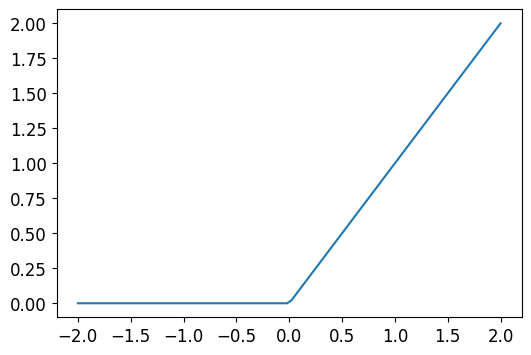

In [136]:
plot_function(F.relu)

>It can be mathematically proven that this little function can solve any computable problem to an arbitrarily high level of accuracy, if you can find the right parameters for ```w1``` and ```w2``` and if you make these matrices big enough. For any arbitrarily wiggly function, we can approximate it as a bunch of lines joined together; to make it closer to the wiggly function, we just have to use shorter lines. This is known as the *universal approximation theorem*. The three lines of code that we have here are known as *layers*. The first and third are known as *linear layers*, and the second line of code is known variously as a *nonlinearity*, or *activation function*.

Just like in the previous section, we can replace this code with something a bit simpler, by taking advantage of PyTorch:

In [137]:
simple_net = nn.Sequential(
    nn.Linear(28*28,30),
    nn.ReLU(),
    nn.Linear(30,1)
)

```nn.Sequential``` creates a module that will call each of the listed layers or functions in turn.

```nn.ReLU``` is a PyTorch module that does exactly the same thing as the ```F.relu``` function. Most functions that can appear in a model also have identical forms that are modules. Generally, it's just a case of replacing ```F``` with ```nn``` and changing the capitalization. When using ```nn.Sequential```, PyTorch requires us to use the module version. Since modules are classes, we have to instantiate them, which is why you see ```nn.ReLU()``` in this example.

Because ```nn.Sequential``` is a module, we can get its parameters, which will return a list of all the parameters of all the modules it contains. Let's try it out! As this is a deeper model, we'll use a lower learning rate and a few more epochs.

In [138]:
learn = Learner(dls, simple_net, opt_func=SGD,
                loss_func=mnist_loss, metrics=batch_accuracy)

In [139]:
#hide_output
learn.fit(40, 0.1)

epoch,train_loss,valid_loss,batch_accuracy,time
0,0.288622,0.415478,0.505397,00:00
1,0.138815,0.217178,0.817959,00:00
2,0.077983,0.111313,0.916585,00:00
3,0.051949,0.076157,0.941609,00:00
4,0.039748,0.059879,0.956820,00:00
5,0.033440,0.050644,0.963690,00:00
6,0.029772,0.044800,0.966634,00:00
7,0.027365,0.040787,0.966634,00:00
8,0.025619,0.037851,0.968597,00:00
9,0.024264,0.035597,0.971050,00:00


We're not showing the 40 lines of output here to save room; the training process is recorded in ```learn.recorder```, with the table of output stored in the ```values``` attribute, so we can plot the accuracy over training as:

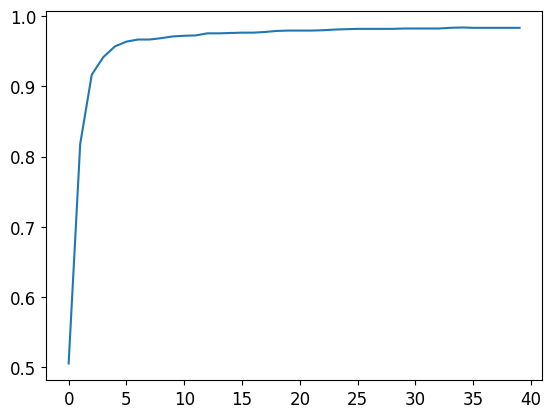

In [140]:
plt.plot(L(learn.recorder.values).itemgot(2));

And we can view the final accuracy:

In [141]:
learn.recorder.values[-1][2]

0.983316957950592